# 04 - Dashboard data mart for Power BI

**Business question.** Weekly reporting was built by hand: exporting order lines, inventory and
forecasts to Excel, pivoting, and pasting into a deck. This notebook produces the tidy star schema
that a Power BI report reads directly, so the weekly refresh becomes "re-run the pipeline, click
refresh".

Output (`data/processed/mart/`):

| Table | Grain | Purpose |
|---|---|---|
| `dim_date` | week | calendar attributes, test-period flag |
| `dim_product` | SKU | category, case pack, price, cost |
| `dim_location` | DC | region, lead time |
| `fact_sales_weekly` | SKU x DC x week | units, revenue, gross margin, orders, promotion |
| `fact_inventory_weekly` | SKU x DC x week | on-hand, value, weeks of cover, excess, backorders |
| `fact_forecast` | SKU x DC x week x method | backtest and forward forecasts with actuals |
| `fact_policy_simulation` | SKU x DC x week x policy | current vs. forecast-based replenishment |

The mart is built with SQL in SQLite (the same statements port to the warehouse) and validated
with row-count, key and reconciliation checks before export.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
RAW, PROC, FIG = Path("../data/raw"), Path("../data/processed"), Path("../reports/figures")
MART = PROC / "mart"; MART.mkdir(parents=True, exist_ok=True)

con = sqlite3.connect(":memory:")
sources = {
    "products": RAW / "products.csv", "locations": RAW / "locations.csv",
    "inventory_snapshots": RAW / "inventory_snapshots.csv",
    "weekly_sales": PROC / "weekly_sales.csv", "forecast_backtest": PROC / "forecast_backtest.csv",
    "forecast_next_quarter": PROC / "forecast_next_quarter.csv",
    "inventory_policy_simulation": PROC / "inventory_policy_simulation.csv",
}
for name, path in sources.items():
    pd.read_csv(path).to_sql(name, con, index=False)
q = lambda sql: pd.read_sql_query(sql, con)

## 1. Dimensions

In [2]:
con.executescript('''
CREATE TABLE dim_date AS
WITH RECURSIVE w(week, week_start) AS (
    SELECT 0, DATE('2023-01-02')
    UNION ALL SELECT week + 1, DATE(week_start, '+7 days') FROM w WHERE week < 168
)
SELECT week AS week_key, week_start,
       DATE(week_start, '+6 days')                    AS week_end,
       CAST(STRFTIME('%Y', DATE(week_start, '+3 days')) AS INTEGER) AS iso_year,
       CAST(STRFTIME('%m', week_start) AS INTEGER)   AS month,
       'Q' || ((CAST(STRFTIME('%m', week_start) AS INTEGER) + 2) / 3) AS quarter,
       CAST(STRFTIME('%Y', week_start) AS INTEGER)   AS year,
       CASE WHEN week >= 117 AND week <= 155 THEN 1 ELSE 0 END AS is_test_period,
       CASE WHEN week > 155 THEN 1 ELSE 0 END        AS is_future
FROM w;

CREATE TABLE dim_product AS
SELECT sku_id, sku_name, category, case_pack, list_price, unit_cost,
       ROUND((list_price - unit_cost) / list_price, 3) AS list_margin_pct
FROM products;

CREATE TABLE dim_location AS
SELECT location_id, location_name, region, lead_time_weeks FROM locations;
''')
print(q("SELECT COUNT(*) AS weeks, MIN(week_start) AS first, MAX(week_start) AS last FROM dim_date"))

   weeks       first        last
0    169  2023-01-02  2026-03-23


## 2. Facts

In [3]:
con.executescript('''
CREATE TABLE fact_sales_weekly AS
SELECT s.sku_id, s.location_id, s.week AS week_key,
       s.units, s.revenue,
       ROUND(s.revenue - s.units * p.unit_cost, 2) AS gross_margin,
       s.orders,
       s.promo_discount,
       CASE WHEN s.promo_discount > 0 THEN 1 ELSE 0 END AS is_promo_week
FROM weekly_sales s JOIN products p USING (sku_id);

CREATE TABLE fact_inventory_weekly AS
WITH s AS (
    SELECT i.sku_id, i.location_id,
           CAST((JULIANDAY(i.snapshot_date) - JULIANDAY('2023-01-02')) / 7 AS INTEGER) AS week_key,
           i.on_hand_units, i.on_order_units, i.backorder_units
    FROM inventory_snapshots i
),
d AS (
    SELECT sku_id, location_id, week AS week_key, units,
           AVG(units) OVER (PARTITION BY sku_id, location_id ORDER BY week
                            ROWS BETWEEN 7 PRECEDING AND CURRENT ROW) AS avg8_units,
           SUM(units) OVER (PARTITION BY sku_id, location_id ORDER BY week
                            ROWS BETWEEN 1 FOLLOWING AND 8 FOLLOWING) AS next8_units,
           COUNT(*)   OVER (PARTITION BY sku_id, location_id ORDER BY week
                            ROWS BETWEEN 1 FOLLOWING AND 8 FOLLOWING) AS next8_weeks
    FROM weekly_sales
)
SELECT s.sku_id, s.location_id, s.week_key,
       s.on_hand_units, s.on_order_units, s.backorder_units,
       ROUND(s.on_hand_units * p.unit_cost, 2) AS inventory_value,
       ROUND(s.on_hand_units / NULLIF(d.avg8_units, 0), 2) AS weeks_of_cover,
       CASE WHEN d.next8_weeks = 8 THEN MAX(s.on_hand_units - d.next8_units, 0) END AS excess_units,
       CASE WHEN d.next8_weeks = 8 THEN ROUND(MAX(s.on_hand_units - d.next8_units, 0) * p.unit_cost, 2) END AS excess_value,
       CASE WHEN s.backorder_units > 0 THEN 1 ELSE 0 END AS is_stockout
FROM s
JOIN d USING (sku_id, location_id, week_key)
JOIN products p USING (sku_id);

CREATE TABLE fact_forecast AS
SELECT sku_id, location_id, target_week AS week_key, origin_week, h AS horizon_weeks,
       split AS forecast_set, method, forecast_units, actual_units
FROM (
    SELECT sku_id, location_id, target_week, origin_week, h, split, 'moving_avg_8w' AS method,
           moving_avg_8w AS forecast_units, actual AS actual_units FROM forecast_backtest
    UNION ALL
    SELECT sku_id, location_id, target_week, origin_week, h, split, 'seasonal_naive',
           seasonal_naive, actual FROM forecast_backtest
    UNION ALL
    SELECT sku_id, location_id, target_week, origin_week, h, split, 'holt_winters',
           holt_winters, actual FROM forecast_backtest
    UNION ALL
    SELECT sku_id, location_id, target_week, origin_week, h, split, 'gradient_boosting',
           gradient_boosting, actual FROM forecast_backtest
    UNION ALL
    SELECT sku_id, location_id, target_week, 155, target_week - 155, 'forward', 'gradient_boosting',
           forecast_units, NULL FROM forecast_next_quarter
);

CREATE TABLE fact_policy_simulation AS
SELECT sku_id, location_id, week AS week_key, policy, demand, on_hand, on_order, backorder,
       filled, ordered, inventory_value, excess_value
FROM inventory_policy_simulation;
''')
for t in ["dim_date", "dim_product", "dim_location", "fact_sales_weekly", "fact_inventory_weekly",
          "fact_forecast", "fact_policy_simulation"]:
    print(f"{t:24s} {q(f'SELECT COUNT(*) AS n FROM {t}').n[0]:>8,d} rows")

dim_date                      169 rows
dim_product                    60 rows
dim_location                    4 rows
fact_sales_weekly          37,440 rows
fact_inventory_weekly      37,440 rows
fact_forecast              53,040 rows
fact_policy_simulation     18,720 rows


## 3. Validation checks

The report should never show numbers that disagree with the source system. These checks fail the
run if keys are orphaned, grains are duplicated, or totals do not reconcile to the raw order lines.

In [4]:
raw_tx = pd.read_csv(RAW / "transactions.csv", usecols=["quantity", "unit_price"])
checks = {
    "sales grain unique": q('''SELECT COUNT(*) = COUNT(DISTINCT sku_id || location_id || week_key) AS ok
                               FROM fact_sales_weekly''').ok[0],
    "inventory grain unique": q('''SELECT COUNT(*) = COUNT(DISTINCT sku_id || location_id || week_key) AS ok
                                   FROM fact_inventory_weekly''').ok[0],
    "no orphan products": q('''SELECT COUNT(*) = 0 AS ok FROM fact_sales_weekly f
                               LEFT JOIN dim_product p USING (sku_id) WHERE p.sku_id IS NULL''').ok[0],
    "no orphan weeks": q('''SELECT COUNT(*) = 0 AS ok FROM fact_forecast f
                            LEFT JOIN dim_date d ON d.week_key = f.week_key WHERE d.week_key IS NULL''').ok[0],
    "units reconcile to order lines": int(q("SELECT SUM(units) AS u FROM fact_sales_weekly").u[0]) == int(raw_tx.quantity.sum()),
    "revenue reconciles (<0.01%)": abs(q("SELECT SUM(revenue) AS r FROM fact_sales_weekly").r[0]
                                      / (raw_tx.quantity * raw_tx.unit_price).sum() - 1) < 1e-4,
}
checks = pd.Series(checks).astype(bool)
assert checks.all(), checks[~checks]
checks

sales grain unique                True
inventory grain unique            True
no orphan products                True
no orphan weeks                   True
units reconcile to order lines    True
revenue reconciles (<0.01%)       True
dtype: bool

## 4. Export for Power BI

Each table is written as a CSV in `data/processed/mart/`. In Power BI the tables are related on
`sku_id`, `location_id` and `week_key` (single-direction, dimension to fact). A small data
dictionary is exported alongside.

In [5]:
tables = ["dim_date", "dim_product", "dim_location", "fact_sales_weekly", "fact_inventory_weekly",
          "fact_forecast", "fact_policy_simulation"]
dictionary = []
for t in tables:
    df = q(f"SELECT * FROM {t}")
    df.to_csv(MART / f"{t}.csv", index=False)
    for c, dt in df.dtypes.items():
        dictionary.append({"table": t, "column": c, "dtype": str(dt)})
pd.DataFrame(dictionary).to_csv(MART / "data_dictionary.csv", index=False)
print(sorted(p.name for p in MART.glob("*.csv")))

['data_dictionary.csv', 'dim_date.csv', 'dim_location.csv', 'dim_product.csv', 'fact_forecast.csv', 'fact_inventory_weekly.csv', 'fact_policy_simulation.csv', 'fact_sales_weekly.csv']


## 5. Dashboard preview

A static preview of the report's executive page, drawn from the mart tables with the same
measures the Power BI report uses (DAX equivalents in the README).

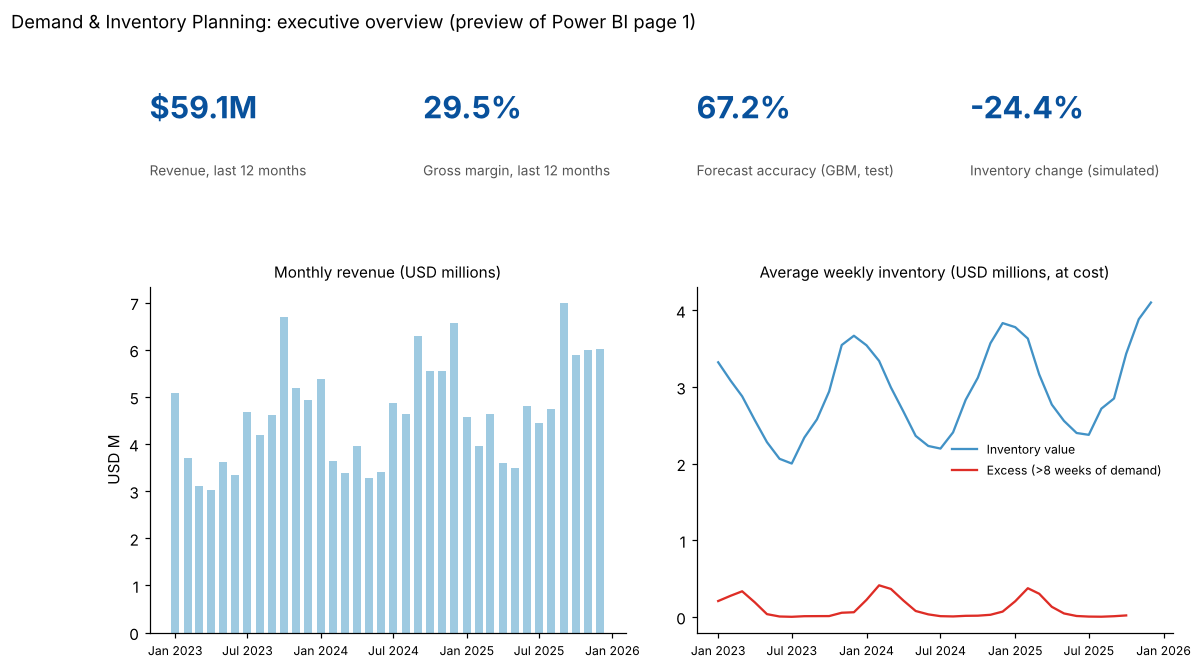

method
gradient_boosting    0.6717
holt_winters         0.5614
moving_avg_8w        0.5637
seasonal_naive       0.5107
Name: accuracy, dtype: float64
policy
current_rule      2990910.0
forecast_based    2260870.0
Name: avg_inventory, dtype: float64


In [6]:
kpi = q('''
SELECT d.year, d.month, SUM(f.revenue) AS revenue, SUM(f.gross_margin) AS gm, SUM(f.units) AS units
FROM fact_sales_weekly f JOIN dim_date d USING (week_key) GROUP BY 1, 2 ORDER BY 1, 2
''')
inv_m = q('''
SELECT d.year, d.month, AVG(t.inventory_value) AS inv_value, AVG(t.excess_value) AS excess_value
FROM (SELECT week_key, SUM(inventory_value) AS inventory_value, SUM(excess_value) AS excess_value
      FROM fact_inventory_weekly GROUP BY 1) t
JOIN dim_date d USING (week_key) GROUP BY 1, 2 ORDER BY 1, 2
''')
acc = q('''
SELECT method, 1 - SUM(ABS(actual_units - forecast_units)) / SUM(actual_units) AS accuracy
FROM fact_forecast WHERE forecast_set = 'test' GROUP BY 1
''').set_index("method").accuracy
pol = q('''
SELECT policy, AVG(v) AS avg_inventory FROM
 (SELECT policy, week_key, SUM(inventory_value) AS v FROM fact_policy_simulation GROUP BY 1, 2)
GROUP BY 1
''').set_index("policy").avg_inventory

last12 = kpi.tail(12)
fig = plt.figure(figsize=(12, 6.5))
gs = fig.add_gridspec(2, 4, height_ratios=[0.6, 2], hspace=0.45, wspace=0.35)
tiles = [
    ("Revenue, last 12 months", f"${last12.revenue.sum() / 1e6:,.1f}M"),
    ("Gross margin, last 12 months", f"{last12.gm.sum() / last12.revenue.sum():.1%}"),
    ("Forecast accuracy (GBM, test)", f"{acc['gradient_boosting']:.1%}"),
    ("Inventory change (simulated)", f"{pol['forecast_based'] / pol['current_rule'] - 1:+.1%}"),
]
for i, (label, value) in enumerate(tiles):
    ax = fig.add_subplot(gs[0, i]); ax.axis("off")
    ax.text(0, 0.65, value, fontsize=20, weight="bold", color="#08519c")
    ax.text(0, 0.1, label, fontsize=9, color="#555555")
ax1 = fig.add_subplot(gs[1, :2])
x = pd.to_datetime(dict(year=kpi.year, month=kpi.month, day=1))
ax1.bar(x, kpi.revenue / 1e6, width=20, color="#9ecae1")
ax1.set_title("Monthly revenue (USD millions)", fontsize=10); ax1.set_ylabel("USD M")
ax2 = fig.add_subplot(gs[1, 2:])
x2 = pd.to_datetime(dict(year=inv_m.year, month=inv_m.month, day=1))
ax2.plot(x2, inv_m.inv_value / 1e6, color="#4292c6", label="Inventory value")
ax2.plot(x2, inv_m.excess_value / 1e6, color="#de2d26", label="Excess (>8 weeks of demand)")
ax2.set_title("Average weekly inventory (USD millions, at cost)", fontsize=10); ax2.legend(frameon=False, fontsize=8)
import matplotlib.dates as mdates
for a in (ax1, ax2):
    a.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    a.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    a.tick_params(axis="x", labelsize=8)
fig.suptitle("Demand & Inventory Planning: executive overview (preview of Power BI page 1)", fontsize=12, x=0.02, ha="left")
fig.savefig(FIG / "04_dashboard_preview.png", bbox_inches="tight")
plt.show()
print(acc.round(4)); print(pol.round(0))

## Findings

* The mart has 3 dimensions and 4 facts: 37,440 weekly sales rows, 37,440 inventory rows, 53,040
  forecast rows (4 methods in the backtest plus the 13-week forward forecast) and 18,720 policy
  simulation rows.
* All validation checks pass. Grains are unique, there are no orphan keys, units reconcile exactly
  to the raw order lines, and revenue reconciles within 0.01%.
* The executive page shows USD 59.1M revenue and 29.5% gross margin over the last 12 months, 67.2%
  test forecast accuracy for the production model, and -24.4% simulated inventory at equal service.
* Refreshing the report now means re-running the notebooks and refreshing the dataset. The manual
  export, pivot and paste steps are gone.